In [3]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay



Dataset shape: (768, 9)

First five rows:
    Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   Pedigree  Age  Outcome  
0     0.627   50        1  
1     0.351   31        0  
2     0.672   32        1  
3     0.167   21        0  
4     2.288   33        1  

Missing values before cleaning:
 Pregnancies      0
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
Pedigree         0
Age              0
Outcome          0
dtype: int64

Outcome counts:
 Outcome
0    500
1    268
Name: count, dtype: int64

Invalid zero counts:
 Glucose            5
BloodPressure     35
Ski

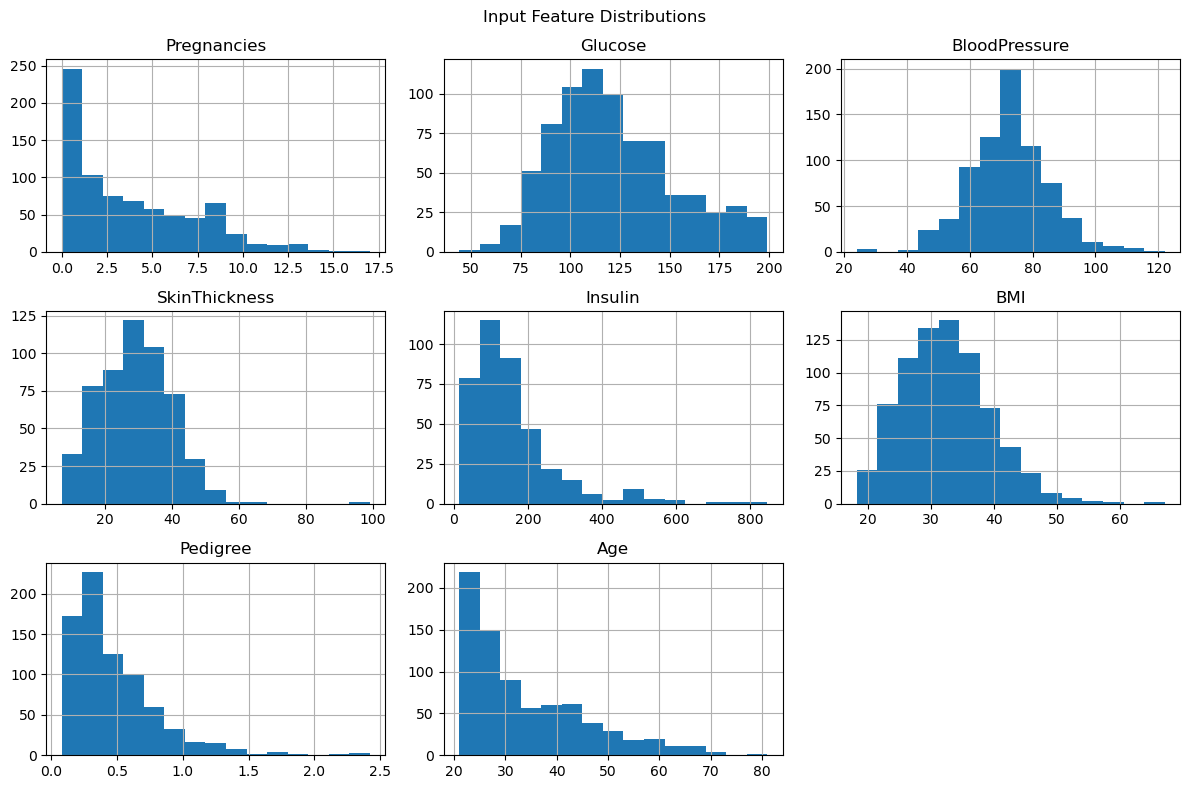

In [4]:
df = pd.read_csv('diabetes.csv')
print('Dataset shape:', df.shape)
print('\nFirst five rows:\n', df.head())
print('\nMissing values before cleaning:\n', df.isna().sum())
print('\nOutcome counts:\n', df['Outcome'].value_counts())

zero_columns = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
print('\nInvalid zero counts:\n', (df[zero_columns] == 0).sum())
df[zero_columns] = df[zero_columns].replace(0, np.nan)
print('\nMissing values after cleaning:\n', df.isna().sum())

df.drop(columns='Outcome').hist(figsize=(12, 8), bins=15)
plt.suptitle('Input Feature Distributions')
plt.tight_layout()
plt.show()



In [5]:
X = df.drop(columns='Outcome')
y = df['Outcome']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print('\nTraining samples:', len(X_train))
print('Testing samples:', len(X_test))



Training samples: 614
Testing samples: 154


In [6]:

k_values = [1, 3, 5, 7, 9, 11, 15, 21]
results = []
for k in k_values:
    model = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    scores = cross_validate(model, X_train, y_train, cv=5, scoring=['precision', 'recall', 'f1'])
    results.append({'K': k, 'Precision': scores['test_precision'].mean(), 'Recall': scores['test_recall'].mean(), 'F1': scores['test_f1'].mean()})

results_df = pd.DataFrame(results)
print('\nFive-fold cross-validation results:\n', results_df.round(3).to_string(index=False))
best_k = int(results_df.loc[results_df['F1'].idxmax(), 'K'])
print('\nSelected K:', best_k)



Five-fold cross-validation results:
  K  Precision  Recall    F1
 1      0.563   0.556 0.558
 3      0.638   0.575 0.603
 5      0.661   0.593 0.621
 7      0.677   0.598 0.632
 9      0.671   0.584 0.624
11      0.693   0.575 0.626
15      0.719   0.608 0.657
21      0.720   0.570 0.633

Selected K: 15


In [7]:

best_model = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), KNeighborsClassifier(n_neighbors=best_k))
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)
print('\nTest accuracy:', accuracy_score(y_test, y_pred))
print('Test precision:', precision_score(y_test, y_pred))
print('Test recall:', recall_score(y_test, y_pred))
print('Test F1-score:', f1_score(y_test, y_pred))
print('\nClassification report:\n', classification_report(y_test, y_pred, target_names=['No diabetes', 'Diabetes']))
print('\nConfusion matrix:\n', confusion_matrix(y_test, y_pred))



Test accuracy: 0.7402597402597403
Test precision: 0.6521739130434783
Test recall: 0.5555555555555556
Test F1-score: 0.6

Classification report:
               precision    recall  f1-score   support

 No diabetes       0.78      0.84      0.81       100
    Diabetes       0.65      0.56      0.60        54

    accuracy                           0.74       154
   macro avg       0.71      0.70      0.70       154
weighted avg       0.73      0.74      0.73       154


Confusion matrix:
 [[84 16]
 [24 30]]


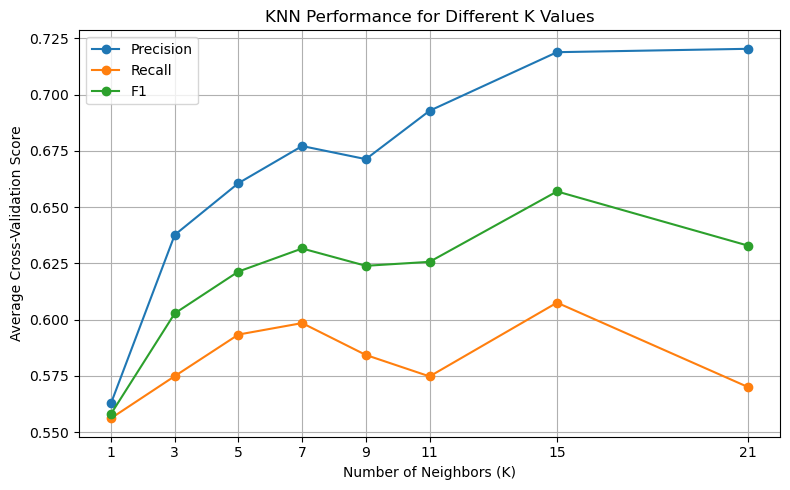

In [8]:

plt.figure(figsize=(8, 5))
for metric in ['Precision', 'Recall', 'F1']:
    plt.plot(results_df['K'], results_df[metric], marker='o', label=metric)
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Average Cross-Validation Score')
plt.title('KNN Performance for Different K Values')
plt.xticks(k_values)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


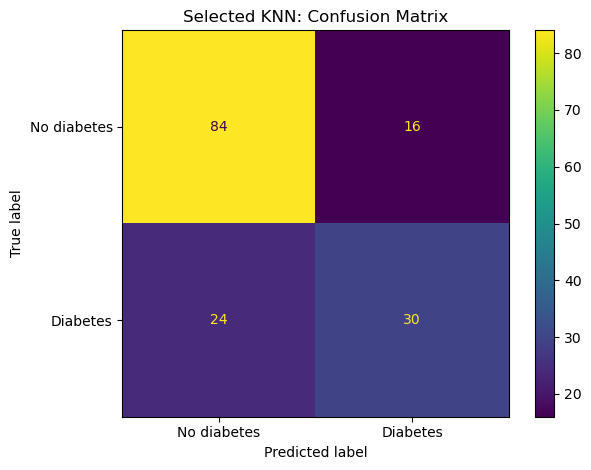

In [9]:

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=[0, 1], display_labels=['No diabetes', 'Diabetes'])
plt.title('Selected KNN: Confusion Matrix')
plt.tight_layout()
plt.show()
